# **TP4 - Principal Component Analysis (PCA)**

<b>Exploratory Data Analysis & Unsuperivsed Learning </b><br>
**Course: Dr. Sothea HAS** <br> 
**TP: Mr. UANN Sreyvi**

-------

**Objective**: In this lab, let's dive into an essential unsupervised learning method: Principal Component Analysis (PCA). PCA is a key technique for dimensionality reduction that simplifies data while preserving its crucial patterns. We will explore PCA from multiple perspectives in this TP.

---------

> **The `Jupyter Notebook` for this TP can be downloaded here: [TP4_PCA.ipynb](https://hassothea.github.io/I5_EDA_ITC/TPs/TP4_PCA.ipynb)**.

-------

## 1. Analyzing US Crime Dataset with PCA

The `USArrests` data available in `Kaggle` provides statistics on arrests for crime including **rape**, **assault** and **murder** in 50 states of the United States in 1973. 

For information, read about the dataset [here](https://www.kaggle.com/datasets/halimedogan/usarrests). We will use PCA to identify which U.S. state was the most dangerous or the safest in 1973.

**A.** Import the data and visualize each column to get a general sense of the dataset.

In [89]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("halimedogan/usarrests")

import pandas as pd

data = pd.read_csv(path + "/usarrests.csv")
data.head()

,Unnamed: 0,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0
3,Arkansas,8.8,190,50,19.5
4,California,9.0,276,91,40.6


**B.** Study correlations between columns of the data using both `Pearson` and `Spearman` correlation coefficients.

- Create pairplot for all columns of the data.

- Given such a pairplot and based on correlations above, is it a good idea to perform dimensional reduction on this dataset? Why?



In [90]:
data.dtypes
# To do
numeric = data.select_dtypes(include=["number"])

In [91]:
numeric.head()

,Murder,Assault,UrbanPop,Rape
0,13.2,236,58,21.2
1,10.0,263,48,44.5
2,8.1,294,80,31.0
3,8.8,190,50,19.5
4,9.0,276,91,40.6


In [92]:
pearson = numeric.corr(method="pearson")
print("Pearson Correlation:")
print(pearson)

Pearson Correlation:
            Murder   Assault  UrbanPop      Rape
Murder    1.000000  0.801873  0.069573  0.563579
Assault   0.801873  1.000000  0.258872  0.665241
UrbanPop  0.069573  0.258872  1.000000  0.411341
Rape      0.563579  0.665241  0.411341  1.000000


In [93]:
spearman = numeric.corr(method="spearman")
print("Spearman Correlation:")
print(spearman)

Spearman Correlation:
            Murder   Assault  UrbanPop      Rape
Murder    1.000000  0.817274  0.106716  0.679427
Assault   0.817274  1.000000  0.275213  0.714368
UrbanPop  0.106716  0.275213  1.000000  0.438107
Rape      0.679427  0.714368  0.438107  1.000000


**C.** Perform reduced PCA (scaled and centered data) on this dataset.

- Create the scree plot of explained variances of the data.

- How many percentage of explained variance is retained by the first two principal components?

In [94]:
# To do
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [95]:
# Perform PCA
pca = PCA()
X_scaled = StandardScaler().fit_transform(numeric)
X_pca = pca.fit_transform(X_scaled)

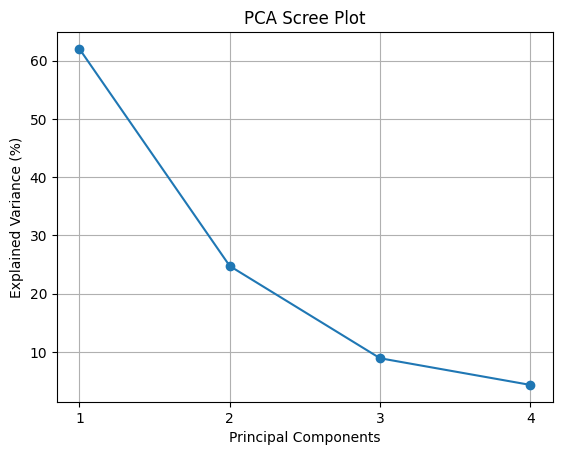

In [96]:
explained_variance = pca.explained_variance_ratio_ * 100
plt.plot(range(1, len(explained_variance) + 1),
         explained_variance, marker="o")

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Scree Plot")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid()
plt.show()

In [97]:
print("PC1:", explained_variance[0], "%")
print("PC2:", explained_variance[1], "%")
print("PC3:", explained_variance[2], "%")
print("PCA4:", explained_variance[3], "%")
print("Total explained variance (PC1 + PC2 + PC3 + PCA4):",
      explained_variance.sum(), "%")

PC1: 62.00603947873733 %
PC2: 24.744128813496037 %
PC3: 8.914079514520749 %
PCA4: 4.335752193245879 %
Total explained variance (PC1 + PC2 + PC3 + PCA4): 100.0 %


**D.** Create circle of correlation of the obtained PCA. Explain this correlation circle.

- Compute the contribution of original variables on the first two PCs (loadings).

- Compute the contribution of each individual on the first two PCs.

/opt/anaconda3/envs/pgm/lib/python3.11/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but PCA was fitted without feature names
  warnings.warn(


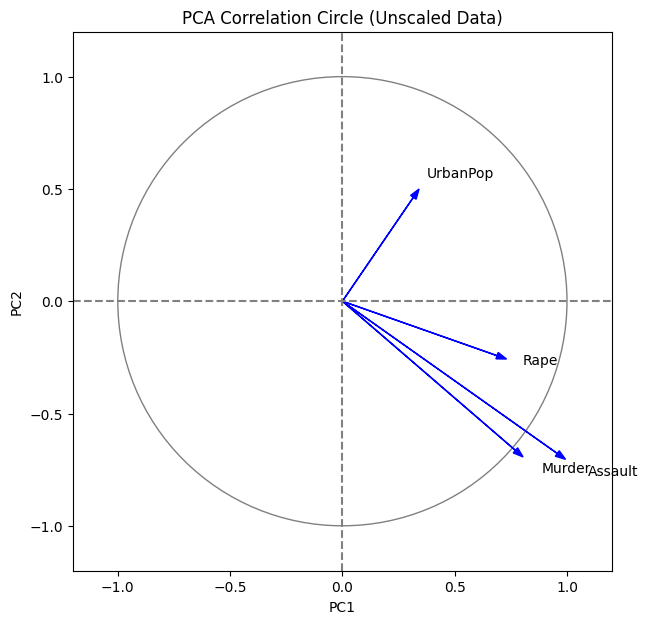

In [98]:
# PCA scores
scores = pca.transform(numeric)

# Correlations between original variables and PCs
loadings = np.corrcoef(
    numeric.values.T,
    scores.T
)[:numeric.shape[1], numeric.shape[1]:]

# Plot correlation circle
fig, ax = plt.subplots(figsize=(7, 7))

circle = plt.Circle((0, 0), 1, fill=False, color="gray")
ax.add_patch(circle)

for i, var in enumerate(numeric.columns):
    ax.arrow(0, 0, loadings[i, 0], loadings[i, 1],
             head_width=0.03, color="blue",
             length_includes_head=True)
    ax.text(loadings[i, 0]*1.1, loadings[i, 1]*1.1, var)

ax.axhline(0, color="gray", linestyle="--")
ax.axvline(0, color="gray", linestyle="--")

ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_aspect("equal")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA Correlation Circle (Unscaled Data)")

plt.show()

**E.** Create biplot of the data on the first factorial plan (PC1 and PC2). Based on this biplot, which US state in 1973 was

- the most dangerous?
- the safest?
- the highly urbanized?
- Verify your answer by checking the situation of those states.

In [99]:
loadings_df = pd.DataFrame(
    loadings[:, :2],
    index=numeric.columns,
    columns=["PC1", "PC2"]
)

print(loadings_df)

               PC1       PC2
Murder    0.804477 -0.693423
Assault   0.993521 -0.703981
UrbanPop  0.341378  0.499731
Rape      0.730977 -0.257360


In [112]:
# Contributions of individuals (%)
contrib = (X_pca[:, :2] ** 2 /
           np.sum(X_pca[:, :2] ** 2, axis=0)) * 100

contrib_df = pd.DataFrame(
    contrib,
    index=data["Unnamed: 0"],
    columns=["PC1 (%)", "PC2 (%)"]
)

print(contrib_df)

                 PC1 (%)    PC2 (%)
Unnamed: 0                         
Alabama         0.783263   2.595723
Alaska          3.066667   2.327394
Arizona         2.506809   1.124411
Arkansas        0.016127   2.533823
California      5.136980   4.810526
Colorado        1.849740   1.970700
Connecticut     1.488503   2.396051
Delaware        0.001835   0.213906
Florida         7.320596   0.003110
Georgia         2.166925   3.305216
Hawaii          0.671663   4.983697
Idaho           2.168292   0.089940
Illinois        1.533234   0.939430
Indiana         0.206021   0.046417
Iowa            4.095505   0.021878
Kansas          0.512063   0.147487
Kentucky        0.454625   1.856214
Louisiana       1.974530   1.533164
Maine           4.632445   0.286271
Maryland        2.507394   0.369560
Massachusetts   0.190592   4.393244
Michigan        3.584751   0.048796
Minnesota       2.310397   0.807776
Mississippi     0.800729  11.579028
Missouri        0.391504   0.140146
Montana         1.133193   0

In [101]:
# Contributions of variables (%) - Unscaled PCA
loadings = pca.components_.T

var_contrib = (loadings[:, :2] ** 2 /
               np.sum(loadings[:, :2] ** 2, axis=0)) * 100

print(pd.DataFrame(
    var_contrib,
    index=numeric.columns,
    columns=["PC1 (%)", "PC2 (%)"]
))

            PC1 (%)    PC2 (%)
Murder    28.718825  17.487524
Assault   34.010315   3.533859
UrbanPop   7.739016  76.179065
Rape      29.531844   2.799553


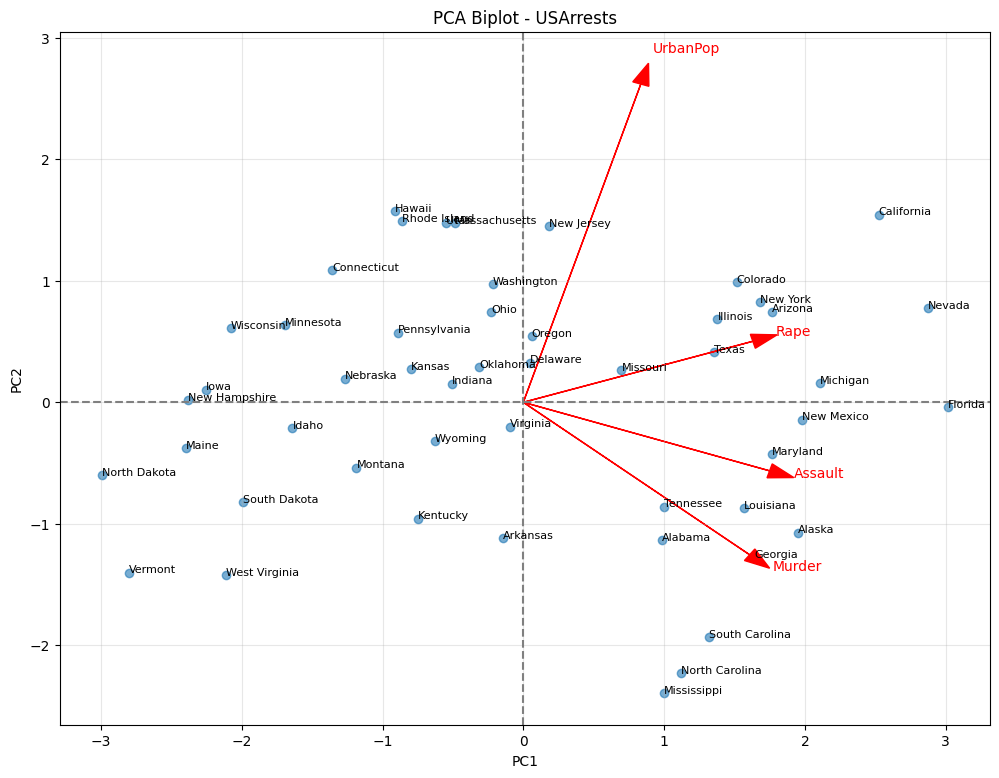

In [113]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 9))

# Plot states
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6)

for i, state in enumerate(data["Unnamed: 0"]):
    plt.text(X_pca[i, 0], X_pca[i, 1], state, fontsize=8)

# Scale variable arrows for visibility
scale = 3

for i, var in enumerate(numeric.columns):
    plt.arrow(0, 0,
              loadings[i, 0] * scale,
              loadings[i, 1] * scale,
              color="red", head_width=0.12)

    plt.text(loadings[i, 0] * scale * 1.1,
             loadings[i, 1] * scale * 1.1,
             var, color="red")

plt.axhline(0, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Biplot - USArrests")
plt.grid(alpha=0.3)
plt.show()

In [115]:
states = ["Florida", "Hawaii","Nevada","Maryland","New Mexico","Michigan","New Jersey", "California","Texas"]

print(data[data["Unnamed: 0"].isin(states)].to_string(index=False))

Unnamed: 0  Murder  Assault  UrbanPop  Rape
California     9.0      276        91  40.6
   Florida    15.4      335        80  31.9
    Hawaii     5.3       46        83  20.2
  Maryland    11.3      300        67  27.8
  Michigan    12.1      255        74  35.1
    Nevada    12.2      252        81  46.0
New Jersey     7.4      159        89  18.8
New Mexico    11.4      285        70  32.1
     Texas    12.7      201        80  25.5


### Neveda , Michigan , New Mexico , Mary land is dangerous 
### Hawai because live there a lot and safe too
### Califonia and New Jersey a lot of people


## I can say North Carolina is the most dangerous place 
##

## 2. Analyzing Auto-MPG dataset with PCA

**A.** Import `Auto-MPG` dataset from kaggle, available [here](https://www.kaggle.com/datasets/uciml/autompg-dataset).

- Compute correlation matrix of quantitative columns of this dataset.

In [103]:
# To do
df_2 = pd.read_csv("auto-mpg.csv")
df_2.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [104]:
df_2.dtypes
df_2.select_dtypes(include=["number"]).head()

,mpg,cylinders,displacement,weight,acceleration,model year,origin
0,18.0,8,307.0,3504,12.0,70,1
1,15.0,8,350.0,3693,11.5,70,1
2,18.0,8,318.0,3436,11.0,70,1
3,16.0,8,304.0,3433,12.0,70,1
4,17.0,8,302.0,3449,10.5,70,1


In [105]:
# Count NaN values in each column
print(df_2.isna().sum())
df_2 = df_2[df_2["horsepower"] != "?"].copy()

mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64


In [106]:
df_2["model year"] = df_2["model year"].astype(object)
df_2["origin"] = df_2["origin"].astype(object)
df_2["horsepower"] = df_2["horsepower"].astype(np.float64)
df_2["cylinders"] = df_2["cylinders"].astype(object)

In [107]:
df_2.dtypes


mpg             float64
cylinders        object
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model year       object
origin           object
car name         object
dtype: object

In [108]:
df_2.select_dtypes(include=["number"]).head()

,mpg,displacement,horsepower,weight,acceleration
0,18.0,307.0,130.0,3504,12.0
1,15.0,350.0,165.0,3693,11.5
2,18.0,318.0,150.0,3436,11.0
3,16.0,304.0,150.0,3433,12.0
4,17.0,302.0,140.0,3449,10.5


**B.** Perform reduced PCA on this dataset.

- How much information or variation is retained by the first two pCs?

In [109]:
# To do


**C.** Create correlation circle and biplot. Comment.

In [110]:
# To do

**D.** Perform variable clustering. Varying hyperperparameters `MAXEIGEN`, how does the number of clusters change. Select the most presentative column of each cluster.

In [111]:
# To do

## 3. Mathematical Problem of PCA

From mathematical point of views, PCA can be seen as a process of searching for a subspace with maximum [projection variance](https://en.wikipedia.org/wiki/Principal_component_analysis) of the data points or searching for its closest [low-rank approximation](https://en.wikipedia.org/wiki/Low-rank_approximation).

Suppose we have a design matrix of observations $X\in\mathbb{R}^{n\times d}$ with centered columns. We aim to mathematically define 1st, 2nd,..., $d$ th principal components of this matrix.

**A. First PC:** a vector $\vec{u}_1\in\mathbb{R}^d$ is the $1$ st PC direction of $X$ if it is the direction (unit vector) in which the projection of observations $X$ achieves maximum variance, i.e.,

$$\vec{u}_1=\arg\max_{\vec{u}:\|\vec{u}\|=1}\|X\vec{u}\|^2.$$

- Show that $\vec{u}_1$ is the first eigenvector of matrix $X^TX$ corresponding to its largest eigenvalue $\lambda_1$.

**B. The $k$ th PC:** Let $\widehat{X}_k=X-\sum_{j=1}^{k-1}X\vec{u}_j\vec{u}_j^T$, then the $k$ th PC direction of $X$ is the vector $\vec{u}_k\in\mathbb{R}^d$ that is orthogonal to all the previous PCs ${\vec{u}_1,\dots,\vec{u}_{k-1}}$ satisfying 

$$\vec{u}_k=\arg\max_{\vec{u}:\|\vec{u}\|=1}\|\widehat{X}_k\vec{u}\|^2.$$

- Show that $\vec{u}_k$ is the $k$ th eigenvector of matrix $X^TX$ corresponding to its $k$ th largest eigenvalue $\lambda_k\leq\lambda_{k-1}\leq\dots\leq \lambda_1$.

**C.** Show that the matrix $\tilde{X}_k=\sum_{j=1}^k\lambda_j\vec{u}_j\vec{u}_j^T$ is the best [low-rank approximation](https://en.wikipedia.org/wiki/Low-rank_approximation) of the original data $X$ w.r.t [Frobenius norm](https://en.wikipedia.org/wiki/Frobenius_norm), i.e.,

$$\tilde{X}_k=\arg\min_{W:\text{rank}(W)\leq k}\|X-W\|_{F}=\arg\min_{W:\text{rank}(W)\leq k}\sqrt{\sum_{j=k+1}^d\lambda_j^2(X-W)}.$$

# Further Readings

- [PCA, sklearn](https://scikit-learn.org/dev/modules/generated/sklearn.decomposition.PCA.html)
- [Low-rank approximation problem](https://en.wikipedia.org/wiki/Low-rank_approximation)
- [Principal Component Analysis (PCA)](https://builtin.com/data-science/step-step-explanation-principal-component-analysis)
- [USarrests Kaggle Dataset](https://www.kaggle.com/datasets/halimedogan/usarrests)
- [Auto-MPG Kaggle Dataset](https://www.kaggle.com/datasets/uciml/autompg-dataset)